In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Metro_Traffic.csv")

df["date_time"] = pd.to_datetime(df["date_time"])
df = df.sort_values("date_time").reset_index(drop=True)

df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

X = df.drop(columns=["traffic_volume", "date_time"])
y = df["traffic_volume"]

split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (38563, 11)
Testing: (9641, 11)


In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": round(
            np.mean(np.abs(y_test - pred)), 2
        ),
        "RMSE": round(
            np.sqrt(np.mean((y_test - pred) ** 2)), 2
        ),
        "R2": round(
            pipeline.score(X_test, y_test), 4
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE")

results_df

,Model,MAE,RMSE,R2
2,Random Forest,296.19,536.20,0.9257
1,Decision Tree,307.43,553.50,0.9209
3,Gradient Boosting,373.21,585.29,0.9115
0,Linear Regression,1538.46,1762.18,0.1980


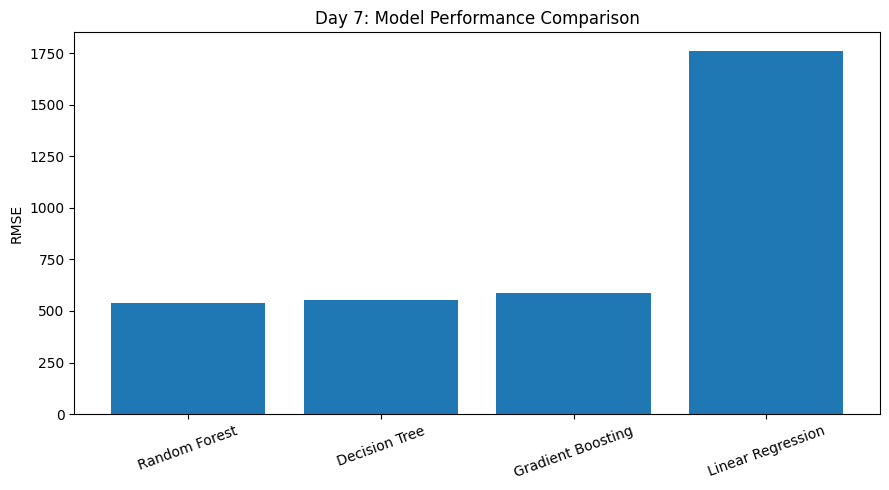

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("RMSE")
plt.title("Day 7: Model Performance Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [5]:
import joblib

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

joblib.dump(best_model, "best_traffic_model.joblib")

print("Best model by test RMSE:", best_name)
print("Model saved successfully.")

Best model by test RMSE: Random Forest
Model saved successfully.
